# Recurring tasks with one shared output

Does a longer absence make a task harder to relearn, beyond the cost of relearning its output weights?

Two tasks share ten true lower features and each uses ten upper features. The learner has 15 fixed lower units (including the ten true features), 30 upper units, and **one scalar output shared by both tasks**. Task identity selects the target only; it is not given to the learner. Targets have Gaussian noise with standard deviation 1.

**Learned-feature methods:** SGD and Autostep learn the upper features and output weights, using 01's original standardization correction. The lower layer stays fixed to isolate the same question as the preceding experiment.

**Frozen-feature baselines:** for each optimizer, supply all twenty true upper features from initialization, alongside ten extra fixed units. Freeze their weights and normalization statistics; learn only the shared output weights. Each task is exactly representable by this fixed basis. Switching tasks still requires learning new output weights, so the baseline measures that unavoidable adaptation cost. No task-specific output weights are stored or restored.

Train alternating 10k-example task blocks for 800k examples, ending on B. From that same checkpoint, train A for 10k, 100k, or 1M examples, then train B for 50k. Every reported error is measured **before learning the example**, against its noisy target. There is no offline readout fitting or absent-task evaluation. Curves show all three absence lengths and all four methods, with five paired seeds per length and identical data across methods. SGD's rate and Autostep's initial rate are exp(-8), matching 01; Autostep's meta-rate is .02. No hyperparameter search.

The relevant comparison is the return curve against the same optimizer's frozen-feature baseline, and whether that gap grows with absence. A small stable gap is acceptable. This experiment does not test a changing lower layer.


In [1]:
from functools import partial
from typing import NamedTuple
from math import comb
import time
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

assert jax.default_backend() == 'gpu', 'GPU required'
RATE, EMA, FLOOR = float(np.exp(-8)), .001, .01
OPT = optax_idbd(meta_lr=.02, init_lr=RATE, autostep=True,
                 tau=1e4, version='squared_inputs')
LABELS = ['SGD: learned features', 'SGD baseline: true frozen features',
          'Autostep: learned features', 'Autostep baseline: true frozen features']
GAPS = [10_000, 100_000, 1_000_000]
CAL = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (10_000, 21)), dtype=jnp.float32)

class State(NamedTuple):
    weights: tuple
    opt: object
    mean: object
    slope: object
    cov: object

@jax.jit
def initialize():
    def seed_init(seed):
        kf, kt, kl, stream = jax.random.split(jax.random.PRNGKey(seed), 4)
        first = jax.random.rademacher(kf, (15,21), dtype=jnp.float32)
        raw = (first @ CAL.T > 2).astype(jnp.float32)
        lower_mean = jnp.full(15, sum(comb(21,k) for k in range(12,22))/2**21)
        lower_sd = jnp.sqrt(lower_mean*(1-lower_mean))
        kt, ko = jax.random.split(kt)
        second = jax.random.rademacher(kt, (2,10,10), dtype=jnp.float32)
        out = jax.random.rademacher(ko, (2,10), dtype=jnp.float32)
        sums = second @ raw[:10]
        candidates = jnp.arange(-10,10)+.5
        rates = (sums[:,:,None,:] > candidates[None,None,:,None]).mean(-1)
        thresholds = candidates[jnp.abs(rates-.3).argmin(-1)]
        upper = RATE*jax.random.uniform(kl,(30,16),minval=-1.,maxval=1.).at[:,-1].set(0.)
        exact = upper.at[:20,:].set(0.)
        exact = exact.at[:20,:10].set(second.reshape(20,10)*lower_sd[:10])
        exact = exact.at[:20,-1].set(second.reshape(20,10)@lower_mean[:10]-thresholds.reshape(20))
        def method_init(method):
            w = jnp.where(method%2==1,exact,upper)
            mean = ((w[:,:-1]@((raw-lower_mean[:,None])/lower_sd[:,None])+w[:,-1,None])>0).mean(1)
            weights = (w,jnp.zeros((1,31)))
            return State(weights,OPT.init(weights),mean,
                         jnp.zeros_like(w).at[:,-1].set(.25),jnp.zeros_like(w))
        return jax.vmap(method_init)(jnp.arange(4)), (first,second,thresholds,out,lower_mean,lower_sd),stream
    states, teachers, keys = jax.vmap(seed_init)(jnp.arange(5))
    return jax.tree.map(lambda a:jnp.swapaxes(a,0,1),states),teachers,keys


def step(s, lower, y, method):
    frozen = method%2==1
    source = jnp.append(lower,1.)
    # Score with the state that existed before seeing this target or updating statistics.
    bits = (s.weights[0]@source>0).astype(jnp.float32)
    h = (bits-s.mean)/jnp.sqrt(jnp.maximum(s.mean*(1-s.mean),FLOOR))
    prediction = (s.weights[1]@jnp.append(h,1.))[0]
    prequential_error = (prediction-y)**2
    def loss(weights):
        w, output = weights
        z = w@source; bits = ltu(z)
        rate = jnp.where(frozen,0.,EMA)
        mean = s.mean+rate*(jax.lax.stop_gradient(bits)-s.mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient((sigmoid*(1-sigmoid))[:,None]*source)
        slope = s.slope+rate*(derivative-s.slope)
        correction = jnp.sum(slope*w,axis=1)
        centered = jax.lax.stop_gradient(bits-mean)
        h = bits-mean+jax.lax.stop_gradient(correction)-correction
        cov = s.cov+rate*(centered[:,None]*(derivative-slope)-s.cov)
        var = mean*(1-mean); floor = jnp.maximum(var,FLOOR)
        change = jnp.sum(cov*w,axis=1)
        h = (h-centered*jnp.where(var>FLOOR,(change-jax.lax.stop_gradient(change))/floor,0.))/jnp.sqrt(floor)
        output_source = jnp.append(h,1.)
        return .5*((output@output_source)[0]-y)**2, (mean,slope,cov,output_source)
    (_, (mean,slope,cov,output_source)), gradients = jax.value_and_grad(loss,has_aux=True)(s.weights)
    gradients = (jnp.where(frozen,0.,gradients[0]),gradients[1])
    updates,opt = OPT.update((gradients,None,(source[None],output_source[None])),s.opt,s.weights)
    updates = jax.tree.map(lambda u,g:jnp.where(method>=2,u,-RATE*g),updates,gradients)
    weights = jax.tree.map(jnp.add,s.weights,updates)
    return State(weights,opt,mean,slope,cov),prequential_error

@jax.jit
def advance(states,keys,teachers,task):
    def sample(carry,_):
        states,keys = carry
        def example(key,t):
            key,kx,kn = jax.random.split(key,3)
            x = jax.random.rademacher(kx,(21,),dtype=jnp.float32)
            first,second,threshold,out,mean,sd = t
            raw = (first@x>2).astype(jnp.float32)
            y = out[task]@(second[task]@raw[:10]>threshold[task]).astype(jnp.float32)+jax.random.normal(kn)
            return key,(raw-mean)/sd,y
        keys,lower,y = jax.vmap(example)(keys,teachers)
        states,error = jax.vmap(jax.vmap(step,in_axes=(0,0,0,None)),in_axes=(0,None,None,0))(states,lower,y,jnp.arange(4))
        return (states,keys),error
    def window(carry,_):
        carry,errors = jax.lax.scan(sample,carry,None,length=1000)
        return carry,errors.mean(0)
    (states,keys),mse = jax.lax.scan(window,(states,keys),None,length=10)
    return states,keys,mse


def run():
    started = time.perf_counter()
    states,teachers,keys = jax.block_until_ready(initialize())
    acquisition = []
    for block in range(80):
        states,keys,mse = jax.block_until_ready(advance(states,keys,teachers,jnp.asarray(block%2)))
        acquisition.append(np.asarray(mse))
    checkpoint,checkpoint_keys = states,keys
    returns = []
    for gap in GAPS:
        states,keys = checkpoint,checkpoint_keys
        absence = []
        for _ in range(gap//10_000):
            states,keys,mse = jax.block_until_ready(advance(states,keys,teachers,jnp.asarray(0)))
            absence.append(np.asarray(mse))
        curve = []
        for _ in range(5):
            states,keys,mse = jax.block_until_ready(advance(states,keys,teachers,jnp.asarray(1)))
            curve.append(np.asarray(mse))
        returns.append(np.concatenate(curve))
    result = dict(acquisition=np.concatenate(acquisition),absence=np.concatenate(absence),returns=np.stack(returns),seconds=time.perf_counter()-started)
    assert np.isfinite(result['returns']).all()
    print(f"GPU runtime (including compilation): {result['seconds']:.1f}s; five paired seeds per absence length")
    for i,gap in enumerate(GAPS):
        print(f'Absence {gap:,}; return RMSE over first / last 10k examples:')
        for m,label in enumerate(LABELS):
            print(f"  {label}: {np.sqrt(result['returns'][i,:10,m].mean()):.3f} / {np.sqrt(result['returns'][i,-10:,m].mean()):.3f}")
    return result


In [2]:
result = run()


GPU runtime (including compilation): 46.1s; five paired seeds per absence length
Absence 10,000; return RMSE over first / last 10k examples:
  SGD: learned features: 1.495 / 1.369
  SGD baseline: true frozen features: 1.308 / 1.000
  Autostep: learned features: 1.204 / 1.156
  Autostep baseline: true frozen features: 1.056 / 1.010
Absence 100,000; return RMSE over first / last 10k examples:
  SGD: learned features: 1.507 / 1.379
  SGD baseline: true frozen features: 1.358 / 1.003
  Autostep: learned features: 1.239 / 1.164
  Autostep baseline: true frozen features: 1.078 / 1.009
Absence 1,000,000; return RMSE over first / last 10k examples:
  SGD: learned features: 1.541 / 1.392
  SGD baseline: true frozen features: 1.356 / 1.002
  Autostep: learned features: 1.420 / 1.187
  Autostep baseline: true frozen features: 1.289 / 1.003


Autostep learned features, 10,000 absent: final 10k on A = 1.202; final 10k back on B = 1.156
Autostep learned features, 100,000 absent: final 10k on A = 1.158; final 10k back on B = 1.164
Autostep learned features, 1,000,000 absent: final 10k on A = 1.069; final 10k back on B = 1.187


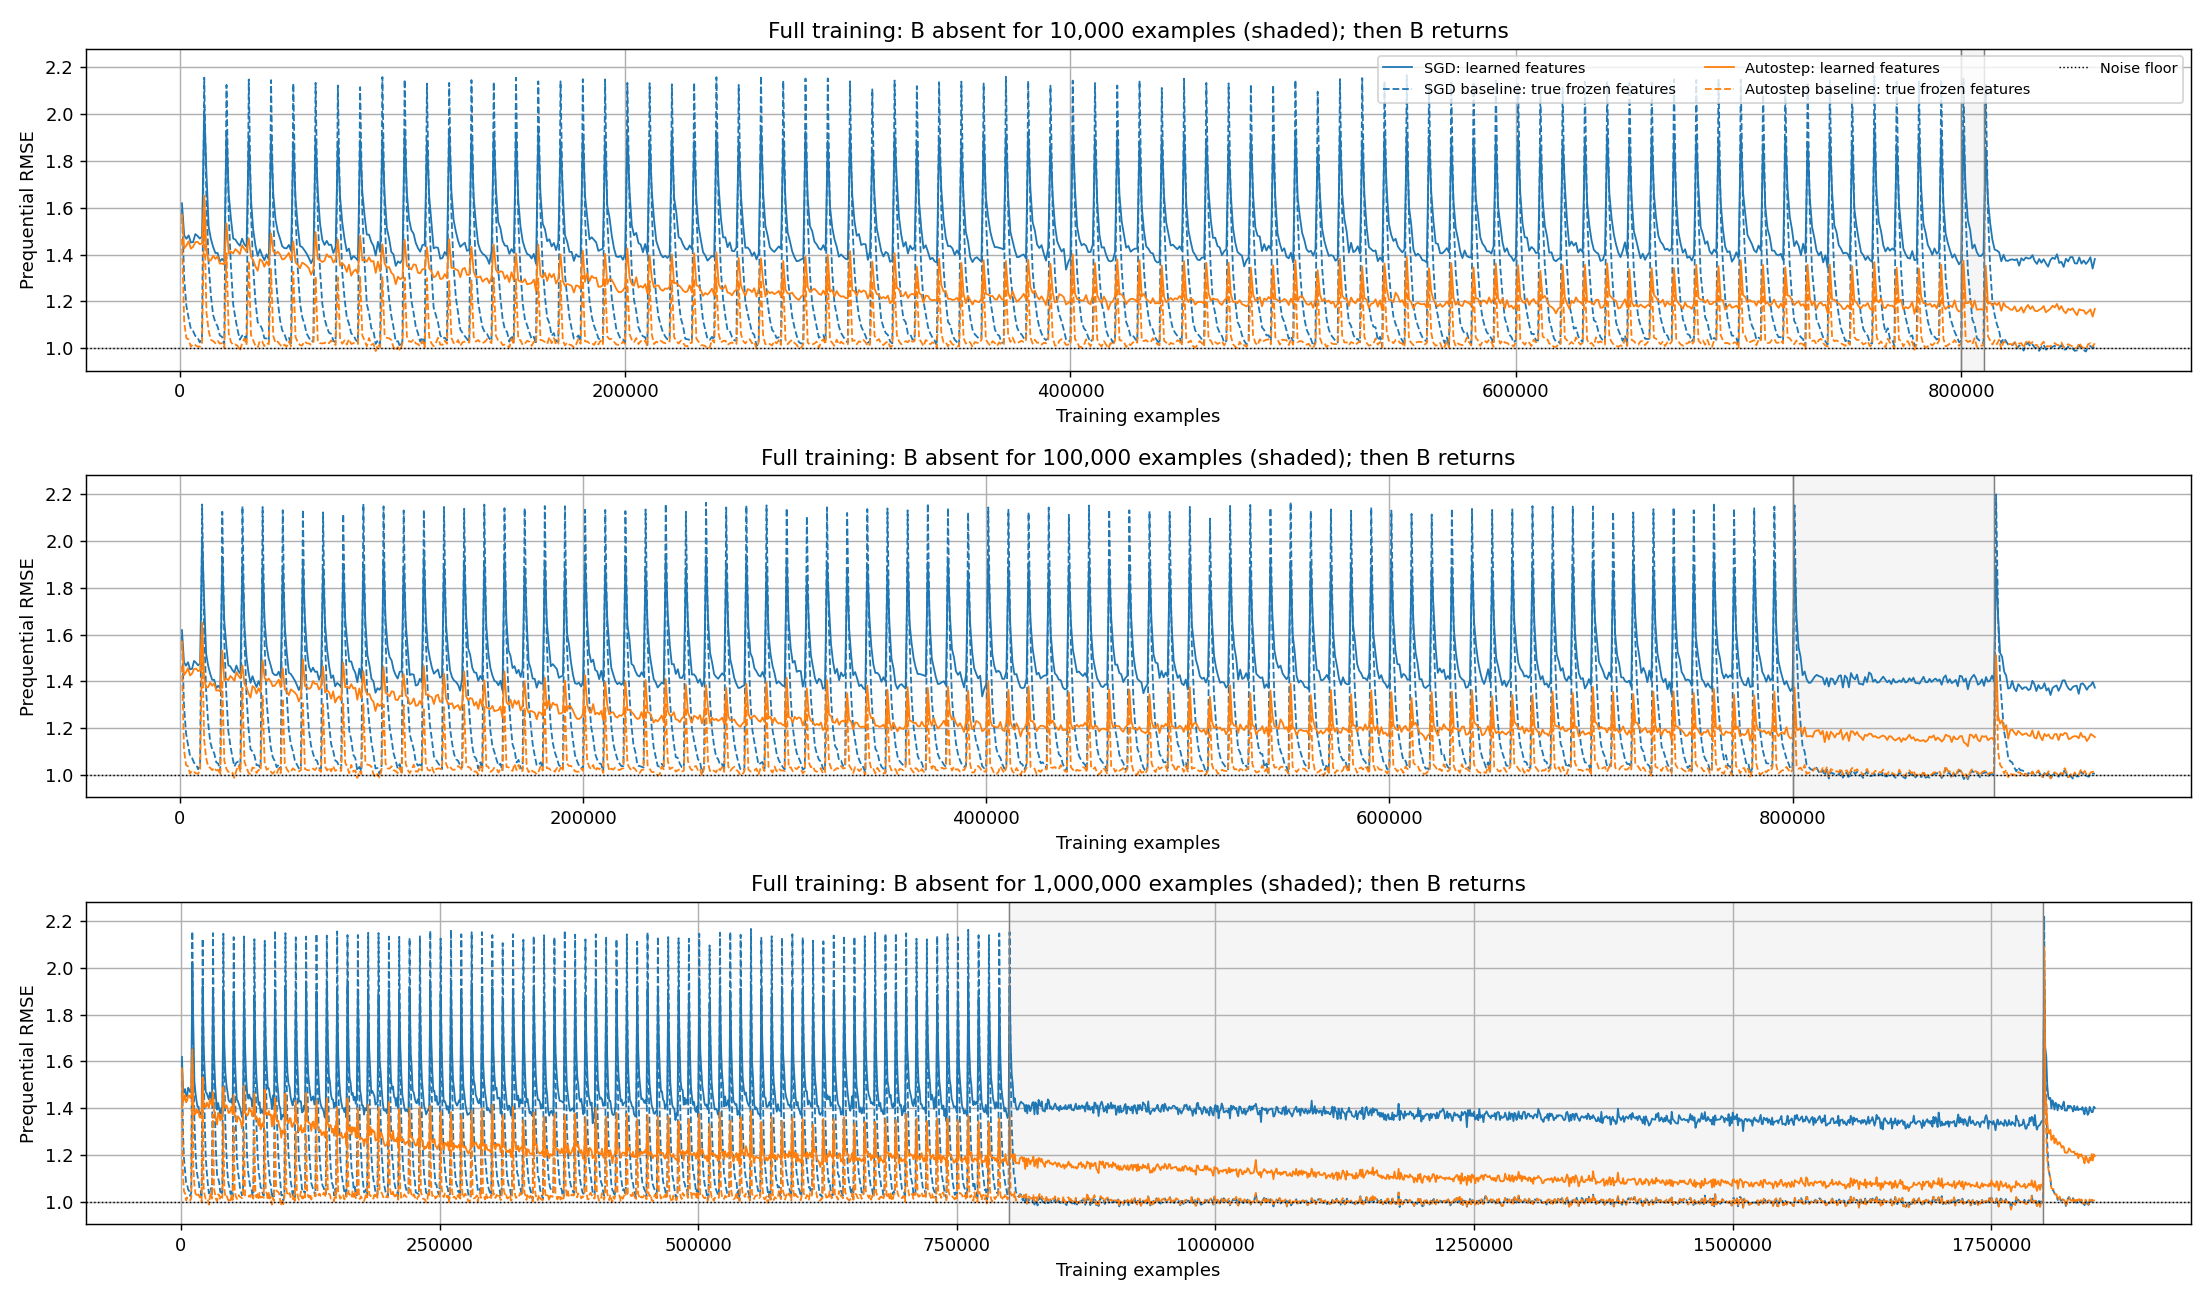

In [3]:
# All curves use 1,000-example windows, including acquisition and absence.
# Each branch starts from the same checkpoint and random stream; its absence
# trajectory is the corresponding prefix of the longest absence trajectory.
fig,axes = plt.subplots(3,1,figsize=(17,10),sharey=True)
colors = ['C0','C0','C1','C1']
for i,(ax,gap) in enumerate(zip(axes,GAPS)):
    mse = np.concatenate([result['acquisition'], result['absence'][:gap//1000], result['returns'][i]])
    for m,label in enumerate(LABELS):
        ax.plot(np.arange(1,len(mse)+1)*1000,np.sqrt(mse[:,m].mean(-1)),
                '--' if m%2 else '-',color=colors[m],linewidth=1,label=label)
    ax.axhline(1.,color='black',linewidth=.8,linestyle=':',label='Noise floor')
    ax.axvline(800_000,color='gray',linewidth=.8)
    ax.axvline(800_000+gap,color='gray',linewidth=.8)
    ax.axvspan(800_000,800_000+gap,color='gray',alpha=.08)
    ax.set(title=f'Full training: B absent for {gap:,} examples (shaded); then B returns',
           xlabel='Training examples',ylabel='Prequential RMSE')
    ax.grid(); ax.ticklabel_format(axis='x',style='plain')
axes[0].legend(fontsize=8,ncol=3)
fig.tight_layout(); plt.show()
for i,gap in enumerate(GAPS):
    a = np.sqrt(result['absence'][gap//1000-10:gap//1000,2].mean())
    b = np.sqrt(result['returns'][i,-10:,2].mean())
    print(f'Autostep learned features, {gap:,} absent: final 10k on A = {a:.3f}; final 10k back on B = {b:.3f}')


## Result

The sweep took 46.1 seconds on GPU, including saving the full absence curves. Both frozen-feature baselines return to roughly RMSE 1.00. Over the final 10k of the 50k return examples, learned-feature SGD gives 1.369, 1.379, and 1.392 as absence increases; Autostep gives 1.156, 1.164, and 1.187.

The larger initial return cost after a long absence is not sufficient evidence of feature loss: Autostep shows it even with exact frozen features. Its baseline's first-10k return RMSE rises from 1.056 to 1.289 across these absence lengths, then recovers to 1.003.

The learned-feature methods already trail their baselines during acquisition. Thus the persistent return gap cannot all be attributed to forgetting. Longer absence produces a modest additional return penalty over this horizon; these three absence lengths do not establish either indefinite deterioration or a plateau. This is a test of learned upper features over fixed lower inputs, not yet of both layers learning.

The full curves use 1,000-example windows throughout. Autostep with learned features remains around 1.17–1.19 near the ends of the final alternating task blocks. After 1M uninterrupted examples on A, its final-10k RMSE is 1.069; after switching back to B for 50k examples it is 1.187. Thus it approaches the noise floor more closely with sustained training on one task, but this run does not establish that it reaches 1.0 or has stopped improving.
